In [1]:
import os
import scipy.stats as stats
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.api as sm
import matplotlib.ticker as ticker
import matplotlib.dates as mpldates
import seaborn as sns
from Regression_utils import *


In [3]:
main_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\Derived All Data With Workover Categories.xlsx")
print(main_df.columns)


Index(['Name', 'Year-Month', 'Hours', 'Water Total', 'PSI', 'Revenue',
       'Metered DM', 'Power Factor', 'Billed DM', 'Billing KWH', 'Fuel Rate',
       'Electrical Bill', 'KWH/Water Ratio', 'Workover Info',
       'Workover Categories', 'Workover Cost', 'Pump Model', 'Pump Number',
       'Plunger Size', 'Install Date', 'Maintenance Cost',
       'Maintenance Comments', 'Workover Count', 'Disposal Rate',
       'KWH per Barrel', 'Cost per KWH', 'Electrical Cost per Barrel',
       'Maintenance Cost per Barrel', 'Workover Cost per Barrel',
       'Revenue per Barrel', 'Income per Barrel', 'Income', 'Total Cost',
       '6 Month Avg KWH', '6 Month Avg Revenue', '6 Month Avg Income',
       '6 Month Avg Total Cost', '6 Month Avg Electrical Cost',
       '6 Month Avg Maintenance Cost', '6 Month Avg Workover Cost',
       '6 Month Avg KWH per Barrel Weighted', '6 Month Avg Cost per KWH',
       '6 Month Avg Electrical Cost per Barrel',
       '6 Month Avg Maintenance Cost per Barrel',
 

Name
ABNEY #2        0
ABNEY #3        1
ALBERTSON #4    1
BASS #4         0
BASS #5         2
               ..
WILLIAMS #6     3
WILLIAMS #7     0
WILLIAMS #8     1
WILLIAMS #9     3
WILSON #4       2
Name: Workover Count, Length: 87, dtype: int64
42
87


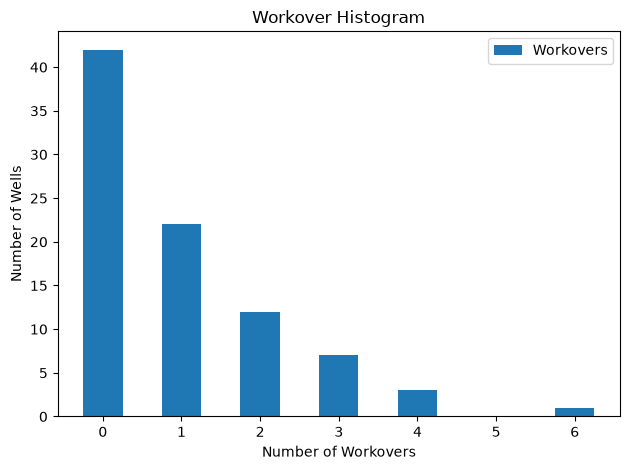

,Name,Year-Month,Hours,Water Total,PSI,Revenue,Metered DM,Power Factor,Billed DM,Billing KWH,...,6 Month Avg Revenue per Barrel,6 Month Avg Income per Barrel,Cumulative Electrical Cost,Cumulative Workover Cost,Cumulative Maintenance Cost,Cumulative Total Cost,Cumulative Income,Cumulative Revenue,Date,Period
0,CUNYUS #5,2019-11,0.00,1,0.0,0.058182,0.0,0.0,0.0,63000.0,...,0.052069,-426.630215,86460.76,0.00,3234.78,89695.54,145964.036202,235659.576202,2019-11-01,2019-11
1,CUNYUS #6,2023-04,0.00,1,0.0,0.065156,172.2,99.4,172.2,44820.0,...,0.061225,-714.368064,192791.25,0.00,113.13,192904.38,293308.988307,486213.368307,2023-04-01,2023-04
2,LAKE #4,2020-04,0.00,10,0.0,0.569309,180.6,99.0,180.6,67800.0,...,0.057873,-745.634230,186886.80,122136.61,18000.00,327023.41,196957.501039,523980.911039,2020-04-01,2020-04
3,COLVILLE #6,2020-02,0.41,1,0.0,0.057899,162.0,87.8,166.1,3300.0,...,0.047609,-629.010504,60095.66,0.00,1712.61,61808.27,-5018.689680,56789.580320,2020-02-01,2020-02
4,BERWALD #5,2022-09,0.00,1,0.0,0.059308,162.0,66.4,162.0,2400.0,...,0.029720,-826.762911,99929.66,0.00,5803.35,105733.01,24973.340252,130706.350252,2022-09-01,2022-09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9391,WILSON #4,2026-03,0.00,0,0.0,0.000000,0.1,31.7,0.1,40.0,...,0.000000,-933.386667,203746.50,101898.61,13771.57,319416.68,92012.238184,411428.918184,2026-03-01,2026-03
9392,WILSON #4,2026-04,0.00,0,0.0,0.000000,0.0,24.2,0.1,40.0,...,0.000000,-933.205000,204679.16,101898.61,13771.57,320349.34,91079.578184,411428.918184,2026-04-01,2026-04
9393,WILSON #4,2026-05,0.00,0,0.0,0.000000,0.0,24.2,0.1,40.0,...,0.000000,-933.226667,205613.05,101898.61,13771.57,321283.23,90145.688184,411428.918184,2026-05-01,2026-05
9394,WILSON #4,2026-06,0.00,0,0.0,NaN,0.0,24.2,0.1,40.0,...,NaN,NaN,206546.94,101898.61,13771.57,322217.12,NaN,NaN,2026-06-01,2026-06


In [4]:
main_df["Workover Count"] = np.where(
    main_df["Workover Cost"] > 1, 
    1, 
    0
)

main_df["Disposal Rate"] = np.where(
    main_df["Hours"] > 0,
    main_df["Water Total"] / main_df["Hours"],
    0
)
# matplotlib doesn't like the pure string values for Year-Month
main_df["Date"] = pd.to_datetime(main_df["Year-Month"])
main_df["Period"] = pd.to_datetime(main_df["Year-Month"]).dt.to_period(freq="M")
#print(main_df["Period"])

#main_df["Year-Month"] = main_df["Year-Month"].dt.to_period("M")

# Get a count of workovers for each well
print(main_df.groupby("Name")["Workover Count"].sum())
workover_counts = main_df.groupby("Name")["Workover Count"].sum()
no_workover = workover_counts[(workover_counts < 1)]
print(len(no_workover))
print(len(workover_counts))
fig, ax = plt.subplots()

max_val = int(max(workover_counts))
bins = range(0, max_val + 2)
ax.hist(workover_counts, bins=bins, align="left", rwidth = 0.5)

ax.set_title("Workover Histogram")
ax.legend(["Workovers"])
ax.set_xlabel("Number of Workovers")
ax.set_ylabel("Number of Wells")
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.xaxis.set_major_locator(ticker.MultipleLocator(1.0))
plt.tight_layout()
plt.show()


#example global variable
TOTAL_WORKOVER_COST = main_df["Workover Cost"].sum()

main_df.dropna(subset = ["Billing KWH", "Electrical Cost per Barrel", "Metered DM"])


In [6]:
main_df[["Billing KWH", "Electrical Cost per Barrel", "Metered DM", "Water Total", "Cost per KWH"]].describe()


,Billing KWH,Electrical Cost per Barrel,Metered DM,Water Total,Cost per KWH
count,9.396000e+03,9396.000000,8856.000000,9396.000000,9396.000000
mean,6.886931e+05,110.212256,163.002064,281713.674330,24.114225
std,2.601855e+06,612.845077,104.925275,207754.683405,320.686199
min,0.000000e+00,-1946.790000,0.000000,-50.000000,-1946.790000
25%,1.440000e+04,0.013833,123.150000,51373.500000,0.054729
50%,9.060000e+04,0.018289,173.000000,324845.500000,0.064376
75%,1.353000e+05,0.033801,199.200000,460225.000000,0.103534
max,2.054960e+07,21737.040000,732.000000,794681.000000,14792.580000


In [17]:
#Making filters for KWH/ Water and Cost per KWH
ratio_filt = main_df["KWH/Water Ratio"] < 100
#Cost per KWH IQR: 0.0732075
cost_filt = (
    (main_df["Cost per KWH"] > 0) &
    (main_df["Cost per KWH"] < 0.30)
)
full_filt = ratio_filt & cost_filt
filtered_df = main_df[full_filt]

filtered_df = filtered_df[filtered_df["Water Total"] > 0]
filtered_df

,Name,Year-Month,Hours,Water Total,PSI,Revenue,Metered DM,Power Factor,Billed DM,Billing KWH,...,6 Month Avg Revenue per Barrel,6 Month Avg Income per Barrel,Cumulative Electrical Cost,Cumulative Workover Cost,Cumulative Maintenance Cost,Cumulative Total Cost,Cumulative Income,Cumulative Revenue,Date,Period
29,BERWALD #5,2025-08,0.02,75,800.000000,4.849694,178.2,88.7,178.2,6900.0,...,0.065277,-451.209903,148522.38,0.0,7062.67,155585.05,16004.163661,1.715892e+05,2025-08-01,2025-08
30,BLUM #9,2022-11,0.00,3165,0.000000,187.722139,732.0,89.7,734.4,278400.0,...,0.059456,-2516.160235,1217819.41,0.0,40905.04,1258724.45,156274.757707,1.414999e+06,2022-11-01,2022-11
31,BLUM #9,2022-06,0.00,1779,0.000000,106.670822,426.0,88.7,432.2,136200.0,...,0.059513,-2.033121,1130607.44,0.0,40791.91,1171399.35,218896.567331,1.390296e+06,2022-06-01,2022-06
32,BLUM #9,2022-05,0.00,1966,0.000000,118.122391,426.0,88.7,432.2,145200.0,...,0.059050,-1.271994,1122424.24,0.0,40791.91,1163216.15,226973.096509,1.390189e+06,2022-05-01,2022-05
34,BLUM #9,2020-12,3.87,4135,500.000000,225.028100,390.0,89.2,393.5,278400.0,...,0.055021,-0.567646,892613.80,0.0,40565.65,933179.45,332782.025809,1.265961e+06,2020-12-01,2020-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8143,COLVILLE #4,2020-05,735.94,480853,806.451613,26314.629667,6.0,94.9,6.0,2700.0,...,0.057297,0.054168,163693.62,0.0,18658.83,182352.45,503492.119741,6.858446e+05,2020-05-01,2020-05
8158,HAMON #4,2022-01,275.32,251265,739.090909,14340.610854,0.0,0.0,0.0,900.0,...,0.028365,-531.136849,307366.00,0.0,20000.00,327366.00,551897.826385,8.792638e+05,2022-01-01,2022-01
8159,CUNYUS #6,2018-01,0.00,253201,775.000000,10406.607371,0.0,0.0,0.0,900.0,...,0.019518,-46.007171,310.39,0.0,0.00,310.39,10145.700772,1.045609e+04,2018-01-01,2018-01
8167,BERWALD #4,2024-05,461.60,243723,789.440000,15900.093793,1.0,39.4,1.0,600.0,...,0.010873,-49.594575,29471.59,0.0,3388.40,32859.99,11675.847989,4.453584e+04,2024-05-01,2024-05


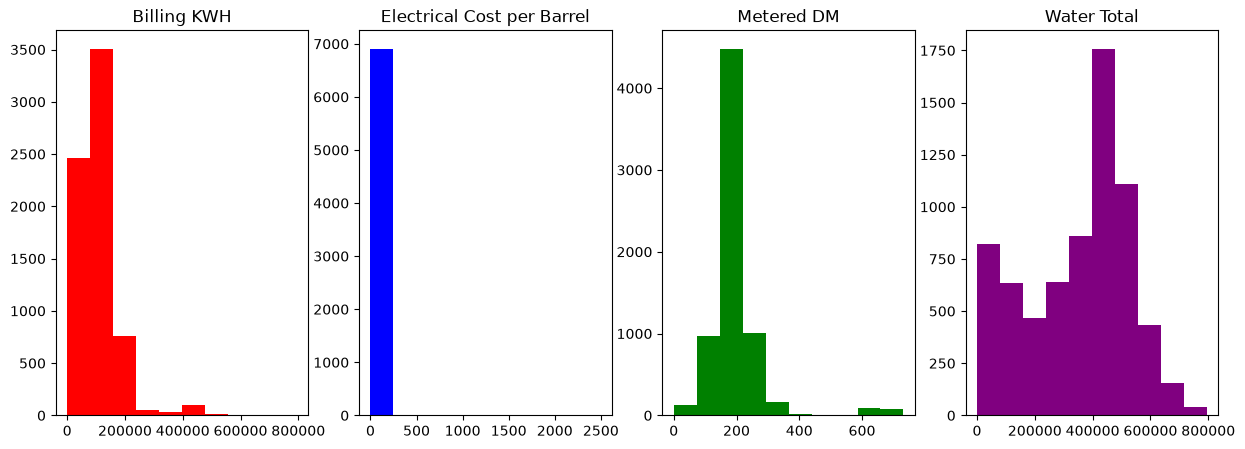

In [18]:
fig, axs = plt.subplots(1, 4, figsize = (15, 5))

axs[0].hist(filtered_df["Billing KWH"], color="red")
axs[0].set_title("Billing KWH")

axs[1].hist(filtered_df["Electrical Cost per Barrel"], color="blue")
axs[1].set_title("Electrical Cost per Barrel")

axs[2].hist(filtered_df["Metered DM"], color="green")
axs[2].set_title("Metered DM")

axs[3].hist(filtered_df["Water Total"], color="purple")
axs[3].set_title("Water Total")
plt.show()

In [19]:
#Electrical cost per barrel is transformed using the Yeo-Johnson transformation
transformed, lam = stats.yeojohnson(filtered_df["Electrical Cost per Barrel"])
filtered_df["Transformed Electrical Cost per Barrel"] = np.nan
filtered_df.loc[
    filtered_df["Electrical Cost per Barrel"].notna(),
    "Transformed Electrical Cost per Barrel"
] = transformed
print("Optimal lambda:", lam)

Optimal lambda: -19.17249891068207


In [20]:
#Water Total transformed using the BoxCox transform
transformed_water, lambda_water = stats.boxcox(filtered_df["Water Total"])

filtered_df["Transformed Water Total"] = transformed_water

print("Optimal lambda:", lambda_water)

Optimal lambda: 0.941301437927114


In [21]:
#transforming the data to achieve normal distribution
filtered_df["Transformed Billing KWH"] = np.sqrt(filtered_df["Billing KWH"])
filtered_df["Transformed Metered DM"] = np.sqrt(filtered_df["Metered DM"])



#Outliers removed to preserve data continuity
filtered_df = filtered_df[filtered_df["Transformed Billing KWH"] < 600]
filtered_df = filtered_df[filtered_df["Transformed Electrical Cost per Barrel"] < 0.030]
filtered_df = filtered_df[(filtered_df["Transformed Metered DM"] < 20) & (filtered_df["Transformed Metered DM"] > 5)]



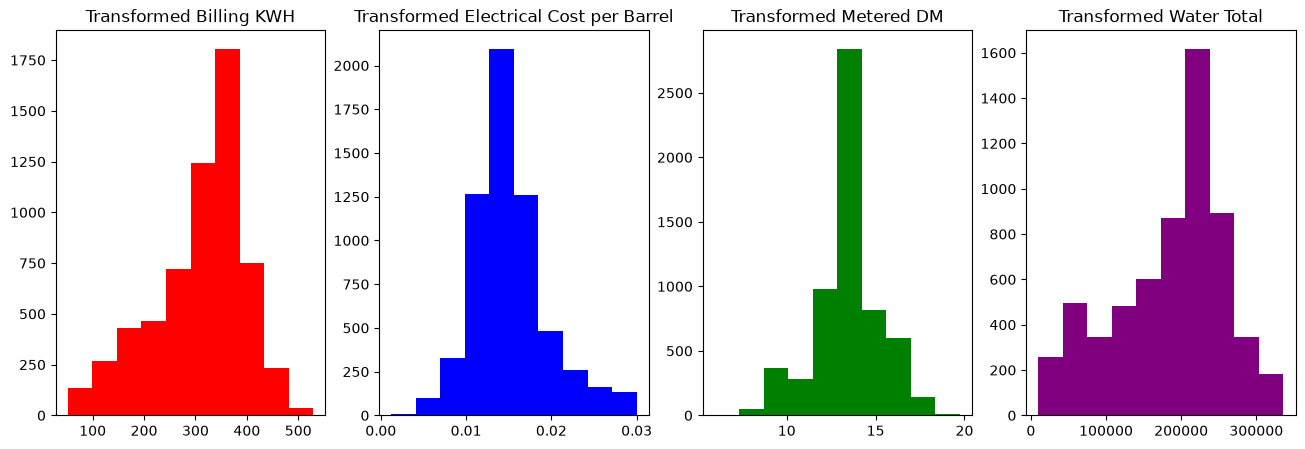

In [22]:
fig, axs = plt.subplots(1, 4, figsize = (16, 5))

axs[0].hist(filtered_df["Transformed Billing KWH"], color="red")
axs[0].set_title("Transformed Billing KWH")

axs[1].hist(filtered_df["Transformed Electrical Cost per Barrel"], color="blue")
axs[1].set_title("Transformed Electrical Cost per Barrel")

axs[2].hist(filtered_df["Transformed Metered DM"], color="green")
axs[2].set_title("Transformed Metered DM")

axs[3].hist(filtered_df["Transformed Water Total"], color="purple")
axs[3].set_title("Transformed Water Total")

plt.show()

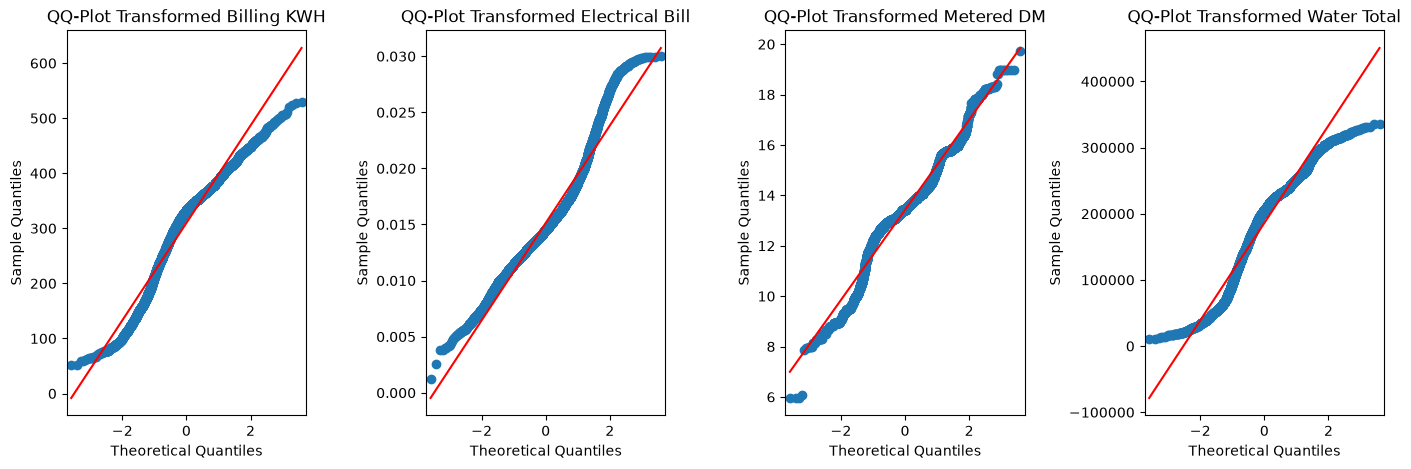

In [32]:
# QQ-plots
fig, axs = plt.subplots(1, 4, figsize = (17, 5))

sm.qqplot(filtered_df["Transformed Billing KWH"], line = "s", ax=axs[0])
axs[0].set_title("QQ-Plot Transformed Billing KWH")

sm.qqplot(filtered_df["Transformed Electrical Cost per Barrel"], line = "s", ax=axs[1])
axs[1].set_title("QQ-Plot Transformed Electrical Bill")

sm.qqplot(filtered_df["Transformed Metered DM"], line = "s", ax=axs[2])
axs[2].set_title("QQ-Plot Transformed Metered DM")

sm.qqplot(filtered_df["Transformed Water Total"], line= "s", ax=axs[3])
axs[3].set_title("QQ-Plot Transformed Water Total")
fig.subplots_adjust(wspace=0.5)
plt.show()


In [24]:
#Date Processing
# Filtering the data to between pre and post workover.
#KWH_filt = KWH_df.drop((KWH_df["Workover Count"] > 0) & (KWH_df["Workover Count"] <2))
#KWH_filt.tail()
main_df["First Workover Date"] = pd.to_datetime("2000-01", format = "%Y-%m")
main_df["First Workover Date"] = main_df["First Workover Date"].dt.to_period("M")
main_df["Second Workover Date"] = pd.to_datetime("2000-01", format = "%Y-%m")
main_df["Second Workover Date"] = main_df["Second Workover Date"].dt.to_period("M")

wells = main_df["Name"].unique()
#print(wells)
#Assigning workover dates to each well
for well in wells:
    well_filt = main_df["Name"] == well
    work_filt = main_df["Workover Count"] == 1
    full_filt = (well_filt) & (work_filt)
    
    # filter example -> main_df[full_filt]["Year-Month"]
    if len(main_df[full_filt]) == 1:
        main_df.loc[full_filt, "First Workover Date"] = main_df[full_filt]["Year-Month"]
        print(well, " 1")
        print(main_df[full_filt]["First Workover Date"])
        
    elif len(main_df[full_filt]) > 1:
        # first date = first workover date
        # second date = second workover date
        first_date = main_df.loc[full_filt, "Year-Month"].iloc[0]
        second_date = main_df.loc[full_filt, "Year-Month"].iloc[1]

        main_df.loc[full_filt, "First Workover Date"] = first_date
        main_df.loc[full_filt, "Second Workover Date"] = second_date
        
        print(well, "> 1")
        print(main_df[full_filt]["First Workover Date"])
        print(main_df.loc[full_filt, "Second Workover Date"])

CUNYUS #6  1
8112    2024-11
Name: First Workover Date, dtype: period[M]
LAKE #4  1
8948    2017-10
Name: First Workover Date, dtype: period[M]
SUNKEL #4 > 1
706     2019-11
7943    2019-11
Name: First Workover Date, dtype: period[M]
706     2022-10
7943    2022-10
Name: Second Workover Date, dtype: period[M]
SUMAN #8  1
888    2025-06
Name: First Workover Date, dtype: period[M]
LAKE #6 > 1
1549    2023-03
5986    2023-03
8958    2023-03
Name: First Workover Date, dtype: period[M]
1549    2017-08
5986    2017-08
8958    2017-08
Name: Second Workover Date, dtype: period[M]
CUNYUS #4 > 1
1536    2022-08
6424    2022-08
8501    2022-08
8503    2022-08
Name: First Workover Date, dtype: period[M]
1536    2020-11
6424    2020-11
8501    2020-11
8503    2020-11
Name: Second Workover Date, dtype: period[M]
BOLDRICK #1 > 1
784     2017-08
7952    2017-08
Name: First Workover Date, dtype: period[M]
784     2019-12
7952    2019-12
Name: Second Workover Date, dtype: period[M]
WILSON #4 > 1
3495   

In [25]:
#Paired t-test for the wells with 1 workover
# attrs is a list of column names
# TODO: implement (ttest_workovers(attrs: list[str], month_count, workover_number))
def ttest_workovers(attrs: list[str], in_df, month_count:int = 6, workover_number:int = 1) -> pd.DataFrame:
    """ Conducts a t-test on both each individual well and all wells for the provided attributes. 
    Attrs is a list of column names from the dataframe of interest. Month count is the number of months 
    to be used in selecting rows before and after a workover. Workover number indicates which (first, second)
    workover we are looking for. 

    returns pd.DataFrame
    """
    rows = []
    # adjust workover number to allow for indexing to start at 1 for easier interpretation
    workover_pos = workover_number - 1

    # dataframes designed to show values 6 months before and after workovers for all wells
    total_before_df = pd.DataFrame()
    total_after_df = pd.DataFrame()

    
    # Paired T-test for first workover date
    for well in wells:
        # Filter to this well
        well_filt = in_df["Name"] == well
    
        # ascending sort oldest to newest records
        well_df = in_df[well_filt].sort_values("Year-Month").reset_index(drop=True)
    
        # Find the row(s) where Year-Month matches the workover date
        workover_rows = well_df[well_df["Workover Count"] == 1]
    
        if workover_rows.empty:
            # No matching workover date found for this well — skip
            continue

        try:
            # Get the integer position of the workover month
            workover_idx = workover_rows.index[0]
            workover_idx = workover_rows.index[workover_pos]
            
            # Slice month_count months before (not including workover month)
            if (workover_idx - month_count) >= 0:
                before_df = well_df.iloc[(workover_idx - month_count):workover_idx]
            else:
                print(f"Not enough months before workover available for {well}")
                continue
        
            # Slice month_count months after (not including workover month)
            if (workover_idx + month_count) < len(well_df):
                after_df = well_df.iloc[workover_idx + 1: workover_idx + month_count + 1]
            else:
                print(f"Not enough months after workover available for {well}")
                continue

                
               # Only keep this well if it has enough months on both sides
            if len(before_df) == month_count and len(after_df) == month_count:
                # concatenate the months before and after workover for each well into a single dataframe
                total_before_df = pd.concat([total_before_df, before_df])
                total_after_df = pd.concat([total_after_df, after_df])
                
                for attr in attrs:
                    before = before_df[attr].to_numpy()
                    after = after_df[attr].to_numpy()
                    
                    #if length of n is less than 2, the T-test will throw and error
                    if len(before) < 2:
                        t_stat, p_value = np.nan, np.nan
                    else: 
                        result = stats.ttest_rel(before, after)
                        t_stat, p_value = result.statistic, result.pvalue

                   #Calculating Variance Ratio
                    var_before = np.var(before, ddof=1)
                    var_after = np.var(after, ddof=1)

                    variance_ratio = max(var_before, var_after)/ min(var_before, var_after)
                    #Welch Test
                    equal_var = variance_ratio <= 4
                    welch_result = stats.ttest_ind(before, after, equal_var=equal_var)
                    w_tstat, w_pvalue = welch_result.statistic, welch_result.pvalue

                    #Wilcoxon Test
                    wilcoxon_result = stats.wilcoxon(before, after)
                    cox_tstat, cox_pvalue = wilcoxon_result.statistic, wilcoxon_result.pvalue
                    #columns for the dataframe
                    rows.append({
                        "Well": well,
                        "Attribute": attr,
                        "Months": month_count,
                        "Workover": workover_number,
                        "N_pairs": len(before),
                        "Paired Sample T_stat": t_stat,
                        "Paired Sample P_value": p_value, 
                        "Welch's T_stat": w_tstat,
                        "Welch's P_value": w_pvalue,
                        "Wilcoxon T_stat": cox_tstat,
                        "Wilcoxon P_value": cox_pvalue,
                    })

                  
        except IndexError as exc:
            print("Index not valid for well", well, exc)
            
    for attr in attrs:
        total_before = total_before_df[attr].to_numpy()
        total_after = total_after_df[attr].to_numpy()
            
        #if length of n is less than 2, the T-test will throw and error
        if len(total_before) < 2:
            t_stat, p_value = np.nan, np.nan
        else:
            #Nan policy is omitted in the tests across multiple wells due to large sample of pairs
            result = stats.ttest_rel(total_before, total_after, nan_policy="omit")
            t_stat, p_value = result.statistic, result.pvalue
            
        #Calculating Variance Ratio
        var_before = np.var(total_before, ddof=1)
        var_after = np.var(total_after, ddof=1)

        variance_ratio = max(var_before, var_after)/ min(var_before, var_after)
        
        #Creating If statement to use Welch's T-test
        equal_var = variance_ratio <= 4
        welch_result = stats.ttest_ind(before, after, equal_var=equal_var)
        w_tstat, w_pvalue = welch_result.statistic, welch_result.pvalue

        wilcoxon_result = stats.wilcoxon(total_before, total_after)
        cox_tstat, cox_pvalue = wilcoxon_result.statistic, wilcoxon_result.pvalue
        
        #columns for the dataframe    
        rows.append({"Well": "All wells", 
                     "Attribute": attr, 
                     "Months": month_count, 
                     "Workover": workover_number,
                     "N_pairs": len(total_before),
                     "Paired Sample T_stat": t_stat,
                     "Paired Sample P_value": p_value,
                     "Welch's T_stat": w_tstat,
                     "Welch's P_value": w_pvalue,
                     "Wilcoxon T_stat": cox_tstat,
                     "Wilcoxon P_value": cox_pvalue,
                    })
        
    return pd.DataFrame(rows)


In [26]:
attributes = ["Billing KWH", 
              "Transformed Billing KWH", 
              "Electrical Cost per Barrel", 
              "Transformed Electrical Cost per Barrel",
              "Metered DM",
              "Transformed Metered DM",
              "Water Total",
              "Transformed Water Total"
             ]
month_counts = [3, 6, 12]
workover_counts = [1, 2]

results = []
for month in month_counts:
    print(f"Testing {month} months")
    for workover in workover_counts:
        print(f"Testing {workover} workovers")
        results.append(ttest_workovers(attributes, filtered_df, month, workover))

ttest_df = pd.concat(results, ignore_index=True)
 

Testing 3 months
Testing 1 workovers
Not enough months before workover available for LAKE #6
Not enough months after workover available for MERRILL #4
Not enough months before workover available for HUGHES #4
Not enough months before workover available for BOLES #1
Not enough months before workover available for WILLIAMS #9


C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_43108\535687242.py:77: RuntimeWarning: divide by zero encountered in scalar divide
  variance_ratio = max(var_before, var_after)/ min(var_before, var_after)
C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_43108\535687242.py:77: RuntimeWarning: divide by zero encountered in scalar divide
  variance_ratio = max(var_before, var_after)/ min(var_before, var_after)
C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unr

Not enough months before workover available for PAYNE #7
Not enough months before workover available for O'DONNELL #4
Testing 2 workovers
Index not valid for well SUNKEL #4 index 1 is out of bounds for axis 0 with size 1
Index not valid for well BOLDRICK #1 index 1 is out of bounds for axis 0 with size 1
Index not valid for well WILSON #4 index 1 is out of bounds for axis 0 with size 1
Index not valid for well KEE #4 index 1 is out of bounds for axis 0 with size 1
Index not valid for well MERRILL #4 index 1 is out of bounds for axis 0 with size 1
Index not valid for well BOLES #1 index 1 is out of bounds for axis 0 with size 1


C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\scipy\stats\_axis_nan_policy.py:431: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  return hypotest_fun_in(*args, **kwds)
C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\scipy\stats\_axis_nan_policy.py:431: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  return hypotest_fun_in(*args, **kwds)


Index not valid for well ALBERTSON #4 index 1 is out of bounds for axis 0 with size 1
Index not valid for well WILLIAMS #8 index 1 is out of bounds for axis 0 with size 1
Index not valid for well THOMPSON #3 index 1 is out of bounds for axis 0 with size 1
Not enough months after workover available for WILLIAMS #6
Not enough months after workover available for SHAW #4
Index not valid for well BLUM #7 index 1 is out of bounds for axis 0 with size 1
Not enough months after workover available for COLVILLE #4
Index not valid for well WILLIAMS #11 index 1 is out of bounds for axis 0 with size 1
Index not valid for well ABNEY #3 index 1 is out of bounds for axis 0 with size 1
Index not valid for well CHRISTIAN #1 index 1 is out of bounds for axis 0 with size 1
Index not valid for well MERRILL #5 index 1 is out of bounds for axis 0 with size 1
Index not valid for well O'DONNELL #4 index 1 is out of bounds for axis 0 with size 1
Testing 6 months
Testing 1 workovers
Not enough months before work

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_43108\535687242.py:77: RuntimeWarning: divide by zero encountered in scalar divide
  variance_ratio = max(var_before, var_after)/ min(var_before, var_after)
C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


Not enough months after workover available for CHRISTIAN #1
Not enough months before workover available for PAYNE #7
Not enough months before workover available for O'DONNELL #4
Testing 2 workovers
Index not valid for well SUNKEL #4 index 1 is out of bounds for axis 0 with size 1
Index not valid for well BOLDRICK #1 index 1 is out of bounds for axis 0 with size 1
Index not valid for well WILSON #4 index 1 is out of bounds for axis 0 with size 1
Index not valid for well KEE #4 index 1 is out of bounds for axis 0 with size 1
Index not valid for well MERRILL #4 index 1 is out of bounds for axis 0 with size 1
Index not valid for well BOLES #1 index 1 is out of bounds for axis 0 with size 1
Index not valid for well ALBERTSON #4 index 1 is out of bounds for axis 0 with size 1
Not enough months before workover available for WILLIAMS #9
Index not valid for well WILLIAMS #8 index 1 is out of bounds for axis 0 with size 1
Index not valid for well THOMPSON #3 index 1 is out of bounds for axis 0 w

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_43108\535687242.py:77: RuntimeWarning: divide by zero encountered in scalar divide
  variance_ratio = max(var_before, var_after)/ min(var_before, var_after)
C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


Not enough months after workover available for SHAW #4
Not enough months after workover available for WILLIAMS #11
Not enough months after workover available for CHRISTIAN #1
Not enough months after workover available for MERRILL #5
Not enough months before workover available for PAYNE #7
Not enough months before workover available for O'DONNELL #4
Testing 2 workovers
Index not valid for well SUNKEL #4 index 1 is out of bounds for axis 0 with size 1
Index not valid for well BOLDRICK #1 index 1 is out of bounds for axis 0 with size 1
Index not valid for well WILSON #4 index 1 is out of bounds for axis 0 with size 1
Index not valid for well KEE #4 index 1 is out of bounds for axis 0 with size 1
Index not valid for well MERRILL #4 index 1 is out of bounds for axis 0 with size 1
Index not valid for well BOLES #1 index 1 is out of bounds for axis 0 with size 1
Not enough months after workover available for MOYAR #2
Not enough months after workover available for MOYAR #3
Index not valid for 

In [27]:
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(ttest_df)

,Well,Attribute,Months,Workover,N_pairs,Paired Sample T_stat,Paired Sample P_value,Welch's T_stat,Welch's P_value,Wilcoxon T_stat,Wilcoxon P_value
0,SUNKEL #4,Billing KWH,3,1,3,-1.386257,2.999871e-01,-1.959533,1.216198e-01,1.0,5.000000e-01
1,SUNKEL #4,Transformed Billing KWH,3,1,3,-1.409865,2.939827e-01,-1.975104,1.194692e-01,1.0,5.000000e-01
2,SUNKEL #4,Electrical Cost per Barrel,3,1,3,0.675219,5.691390e-01,0.750590,5.219396e-01,2.0,7.500000e-01
3,SUNKEL #4,Transformed Electrical Cost per Barrel,3,1,3,0.565885,6.284965e-01,0.645340,5.746516e-01,2.0,7.500000e-01
4,SUNKEL #4,Metered DM,3,1,3,1.236131,3.418894e-01,0.991585,4.191922e-01,1.0,5.000000e-01
5,SUNKEL #4,Transformed Metered DM,3,1,3,1.191592,3.556507e-01,0.950134,4.356063e-01,1.0,5.000000e-01
6,SUNKEL #4,Water Total,3,1,3,-0.572322,6.248625e-01,-0.757766,4.907811e-01,1.0,5.000000e-01
7,SUNKEL #4,Transformed Water Total,3,1,3,-0.586438,6.169534e-01,-0.775129,4.815362e-01,1.0,5.000000e-01
8,CUNYUS #4,Billing KWH,3,1,3,0.158681,8.884951e-01,0.198290,8.524886e-01,3.0,1.000000e+00
9,CUNYUS #4,Transformed Billing KWH,3,1,3,0.235034,8.360543e-01,0.293864,7.834790e-01,3.0,1.000000e+00


In [28]:
cols = ["Paired Sample P_value", "Welch's P_value", "Wilcoxon P_value"]
ttest_display = ttest_df.copy()
ttest_display[cols] = ttest_display[cols].round(4)

Paired_Sample_df = ttest_display[["Well", "Attribute", "Months", "Workover", "N_pairs", "Paired Sample T_stat", "Paired Sample P_value"]]
Welch_df = ttest_display[["Well", "Attribute", "Months", "Workover", "N_pairs", "Welch's T_stat", "Welch's P_value"]]
Wilcoxon_df = ttest_display[["Well", "Attribute", "Months", "Workover", "N_pairs", "Wilcoxon T_stat", "Wilcoxon P_value"]]

In [29]:
Paired_Sample_df["Significant .05"] = Paired_Sample_df["Paired Sample P_value"] <= 0.05
Welch_df["Significant .05"] = Welch_df["Welch's P_value"] <=0.05
Wilcoxon_df["Significant .05"] = Wilcoxon_df["Wilcoxon P_value"] <= 0.05


Paired_Sample_df["Significant .01"] = Paired_Sample_df["Paired Sample P_value"] <= 0.01
Welch_df["Significant .01"] = Welch_df["Welch's P_value"] <=0.01
Wilcoxon_df["Significant .01"] = Wilcoxon_df["Wilcoxon P_value"] <= 0.01



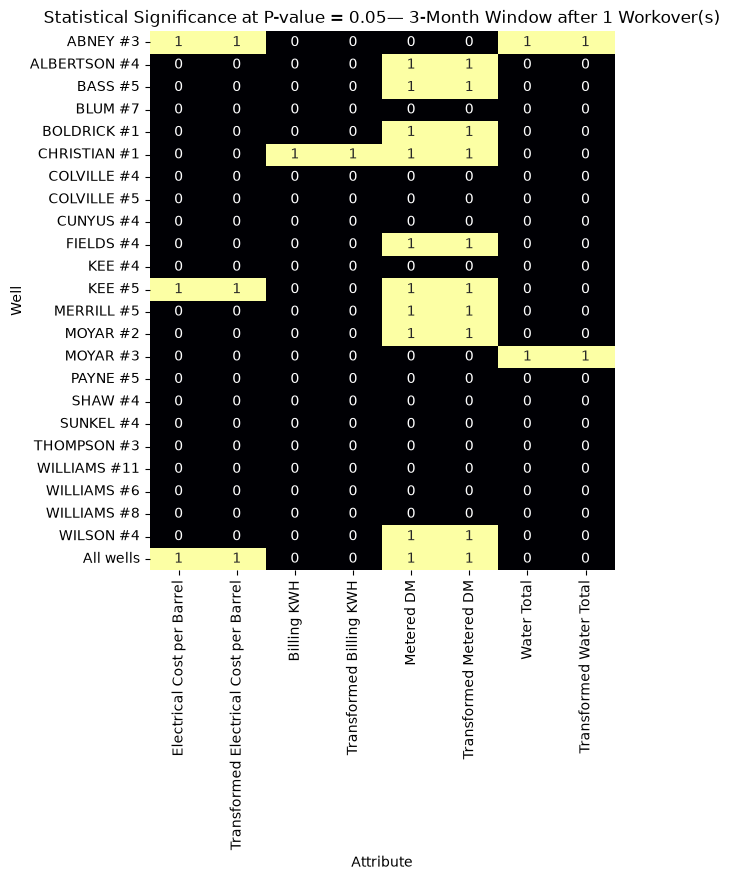

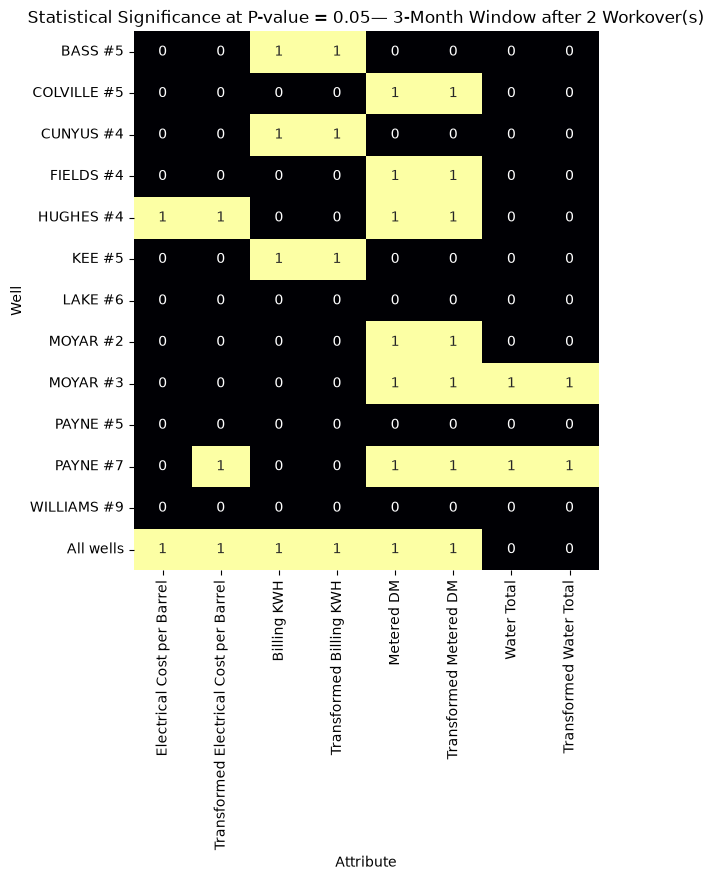

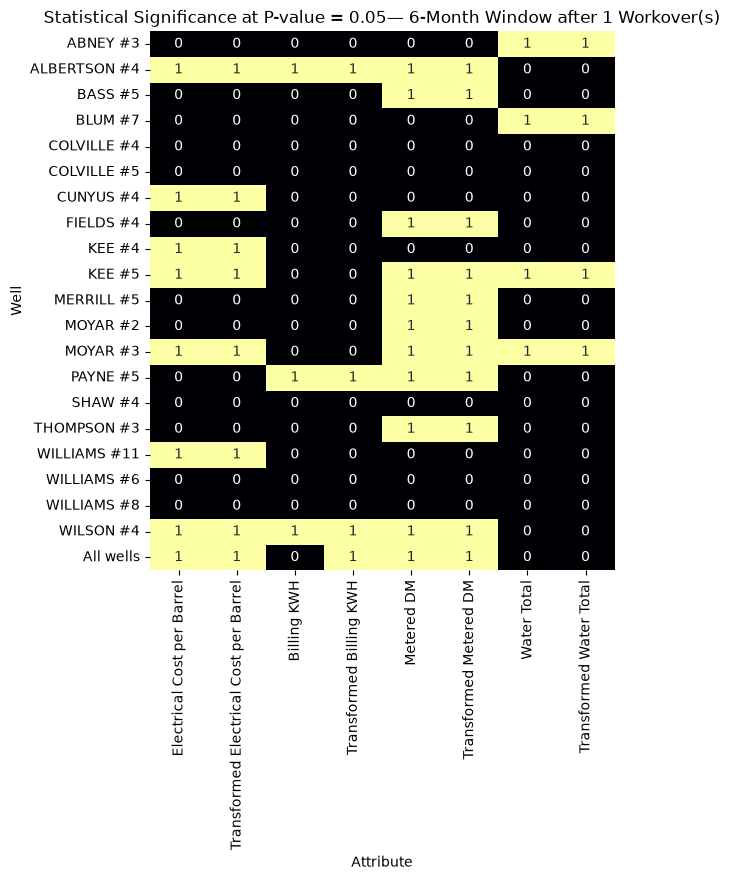

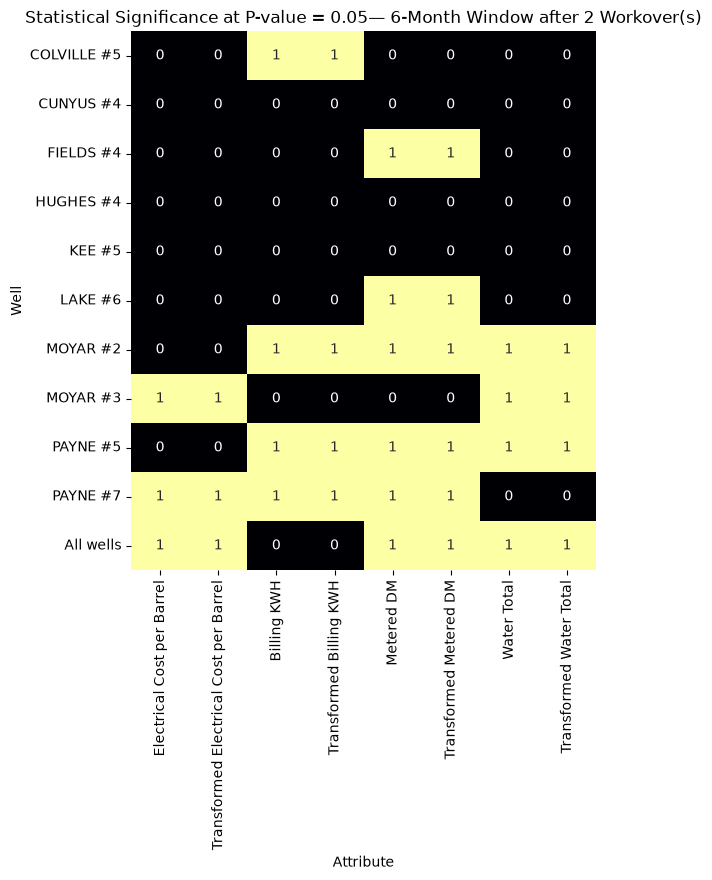

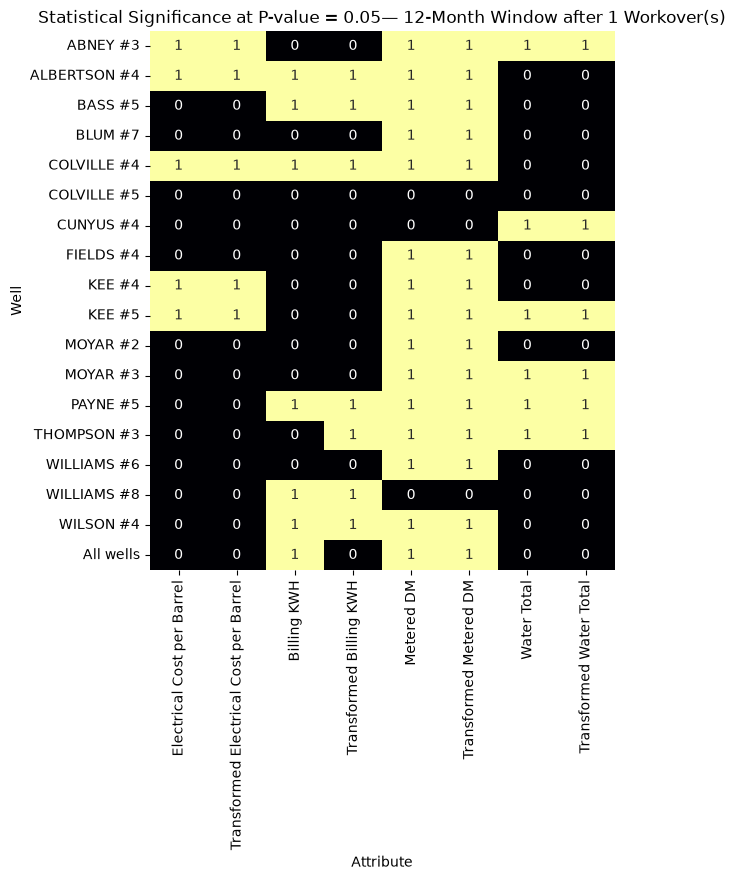

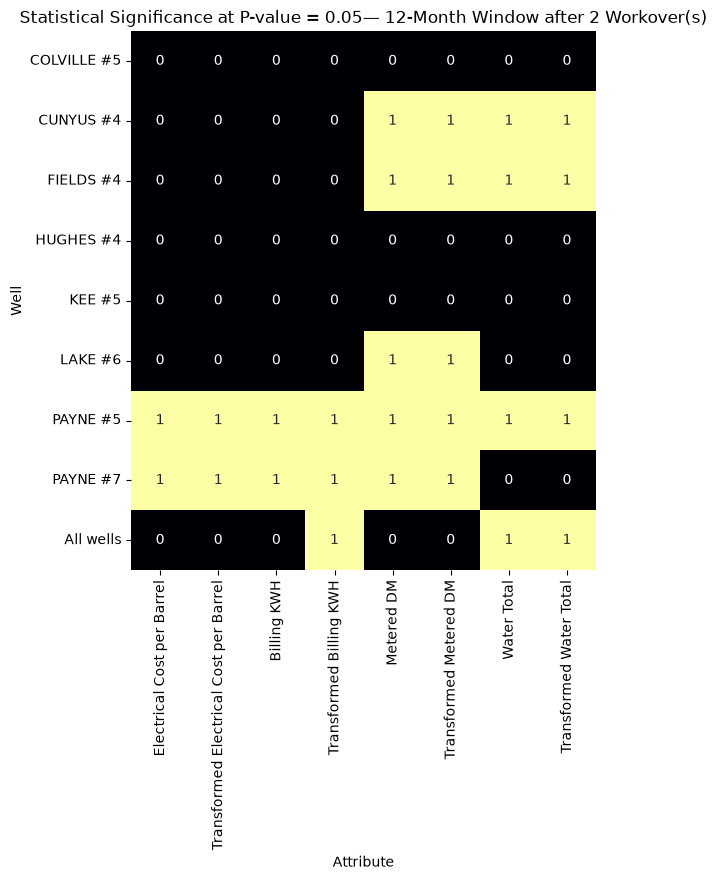

In [30]:
attribute_order = [
    "Electrical Cost per Barrel",
    "Transformed Electrical Cost per Barrel",
    "Billing KWH",
    "Transformed Billing KWH",
    "Metered DM",
    "Transformed Metered DM",
    "Water Total",
    "Transformed Water Total"
]

window_test = [3, 6, 12]
workovers_test = [1,2]
for window in window_test:
    for work in workovers_test:
        #creating the dataframe for the binary matrix using the lists above
        window_df = Paired_Sample_df[(Paired_Sample_df["Months"] == window) & (Paired_Sample_df["Workover"] == work)]
        binary_matrix = window_df.pivot(index = "Well", columns = "Attribute", values = "Significant .05")
        binary_matrix = binary_matrix.astype(int)
        #changing the order of the columns
        binary_matrix = binary_matrix.reindex(columns = attribute_order)
        #changing the order of the index
        well_order = [
            well for well in binary_matrix.index
            if well != "All wells"
        ]
        
        if "All wells" in binary_matrix.index:
            well_order.append("All wells")
        
        binary_matrix = binary_matrix.reindex(well_order)
        
        #plotting the heatmap figure
        plt.figure(figsize=(6, 7))
        sns.heatmap(
            binary_matrix, 
            annot = True,
            cmap = "inferno",
            vmin = 0,
            vmax = 1,
            cbar = False
        )
        
        plt.title(f"Statistical Significance at P-value = 0.05— {window}-Month Window after {work} Workover(s)")
        plt.xlabel("Attribute")
        plt.ylabel("Well")
        filename = f"Paired_Sample_T-test_Binary_Matrix_{window}_{work}.jpeg"
        plt.savefig(filename, dpi=200, bbox_inches="tight")
        plt.show()


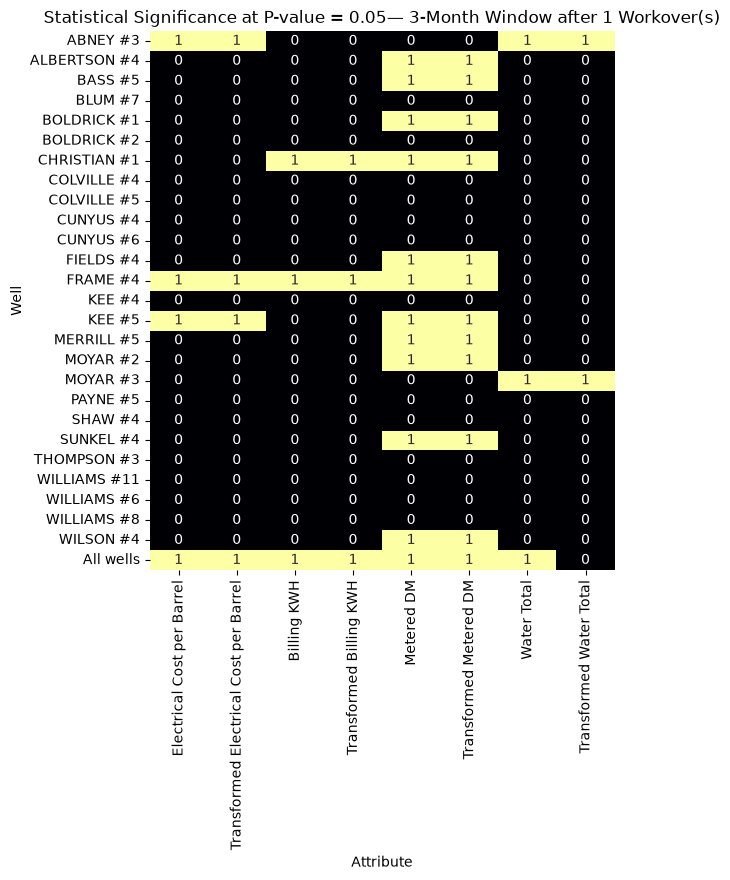

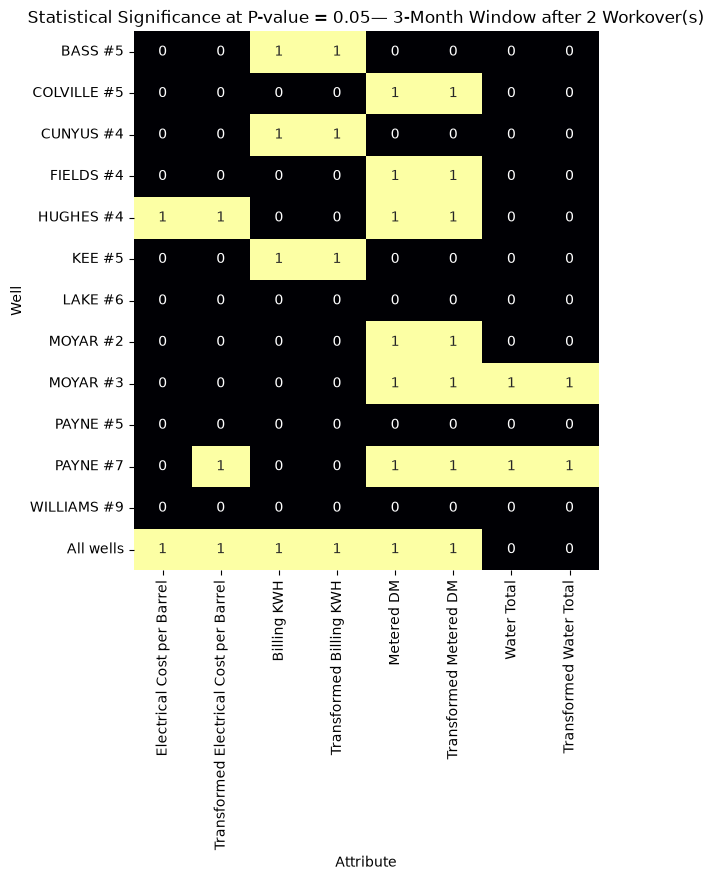

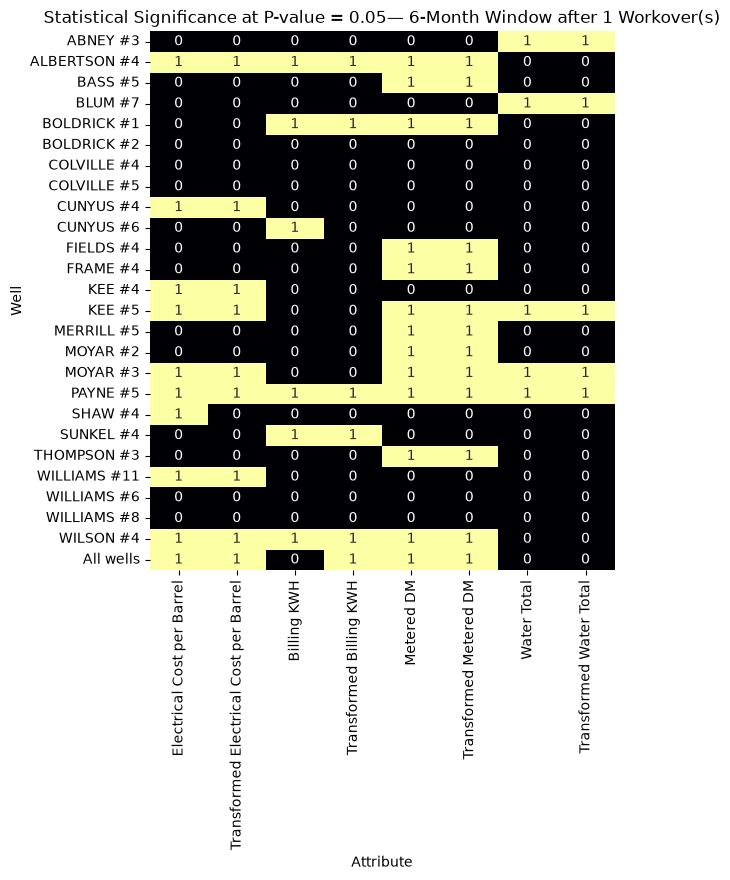

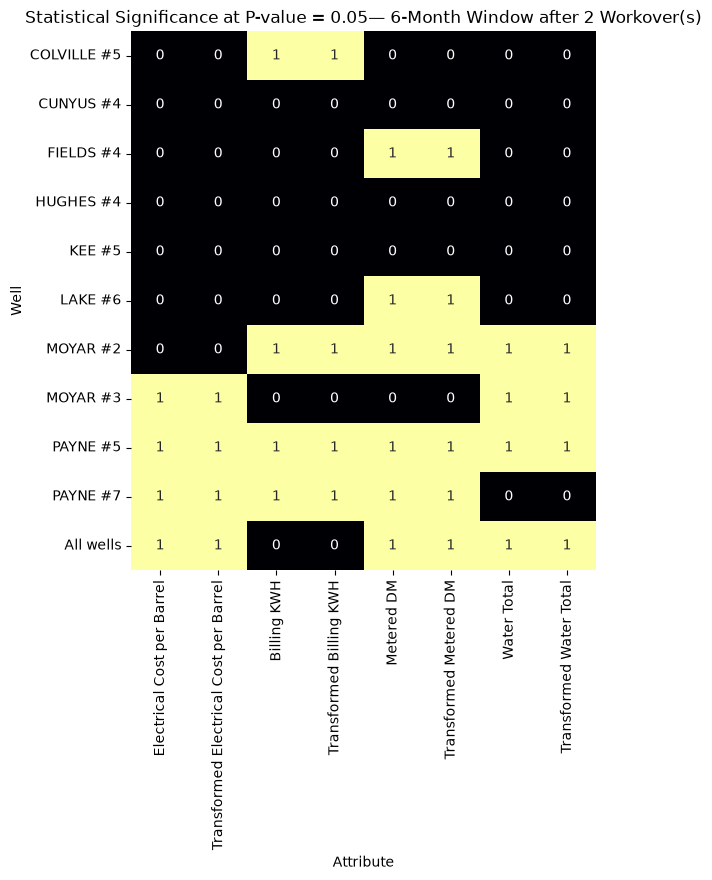

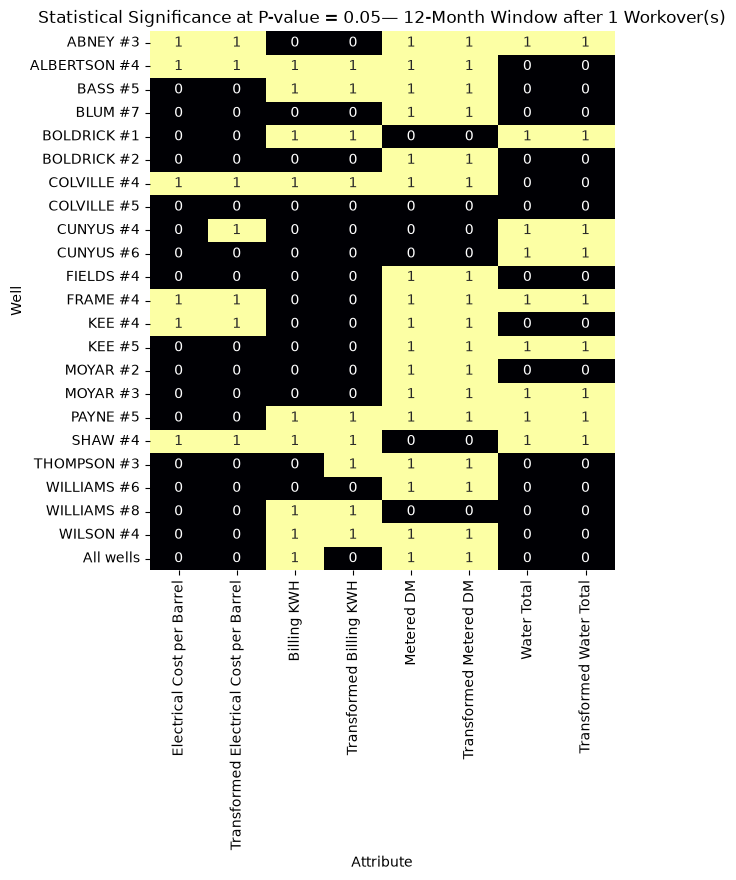

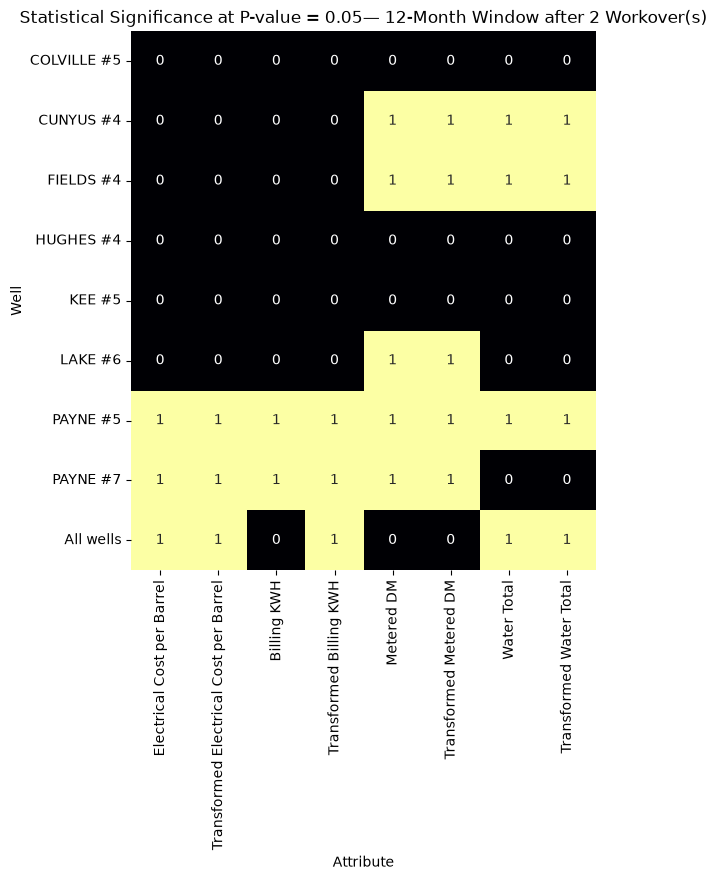

In [41]:
attribute_order = [
    "Electrical Cost per Barrel",
    "Transformed Electrical Cost per Barrel",
    "Billing KWH",
    "Transformed Billing KWH",
    "Metered DM",
    "Transformed Metered DM",
    "Water Total",
    "Transformed Water Total"
]

window_test = [3, 6, 12]
workovers_test = [1,2]
for window in window_test:
    for work in workovers_test:
        #creating the dataframe for the binary matrix using the lists above
        window_df = Paired_Sample_df[(Welch_df["Months"] == window) & (Welch_df["Workover"] == work)]
        binary_matrix = window_df.pivot(index = "Well", columns = "Attribute", values = "Significant .05")
        binary_matrix = binary_matrix.astype(int)
        #changing the order of the columns
        binary_matrix = binary_matrix.reindex(columns = attribute_order)
        #changing the order of the index
        well_order = [
            well for well in binary_matrix.index
            if well != "All wells"
        ]
        
        if "All wells" in binary_matrix.index:
            well_order.append("All wells")
        
        binary_matrix = binary_matrix.reindex(well_order)
        
        #plotting the heatmap figure
        plt.figure(figsize=(6, 7))
        sns.heatmap(
            binary_matrix, 
            annot = True,
            cmap = "inferno",
            vmin = 0,
            vmax = 1,
            cbar = False
        )
        
        plt.title(f"Statistical Significance at P-value = 0.05— {window}-Month Window after {work} Workover(s)")
        plt.xlabel("Attribute")
        plt.ylabel("Well")
        filename = f"Welch_T-test_Binary_Matrix_{window}_{work}.jpeg"
        plt.savefig(filename, dpi=200, bbox_inches="tight")
        
        plt.show()

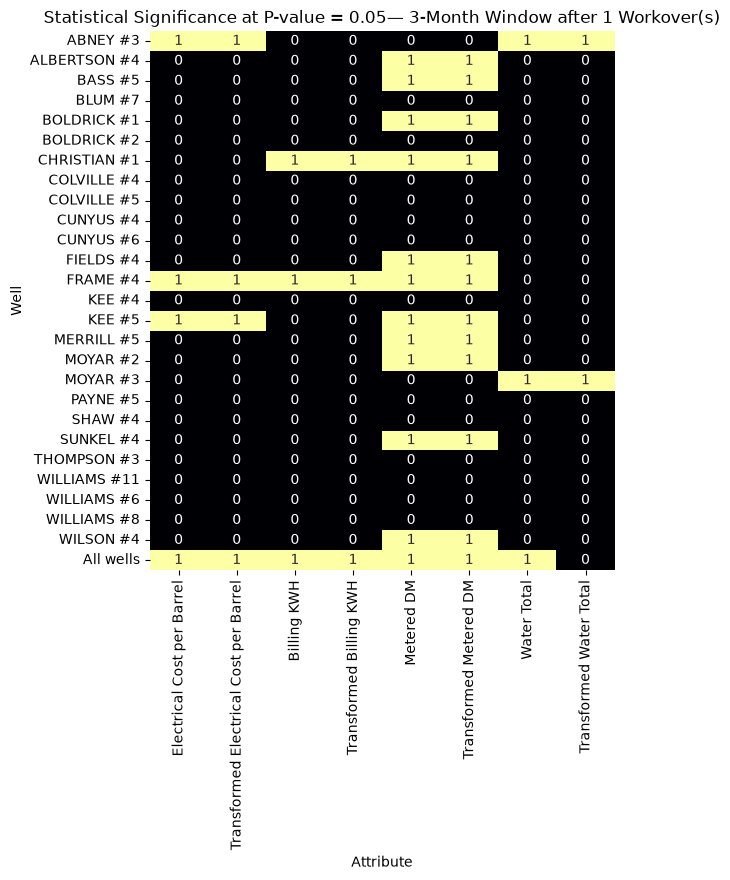

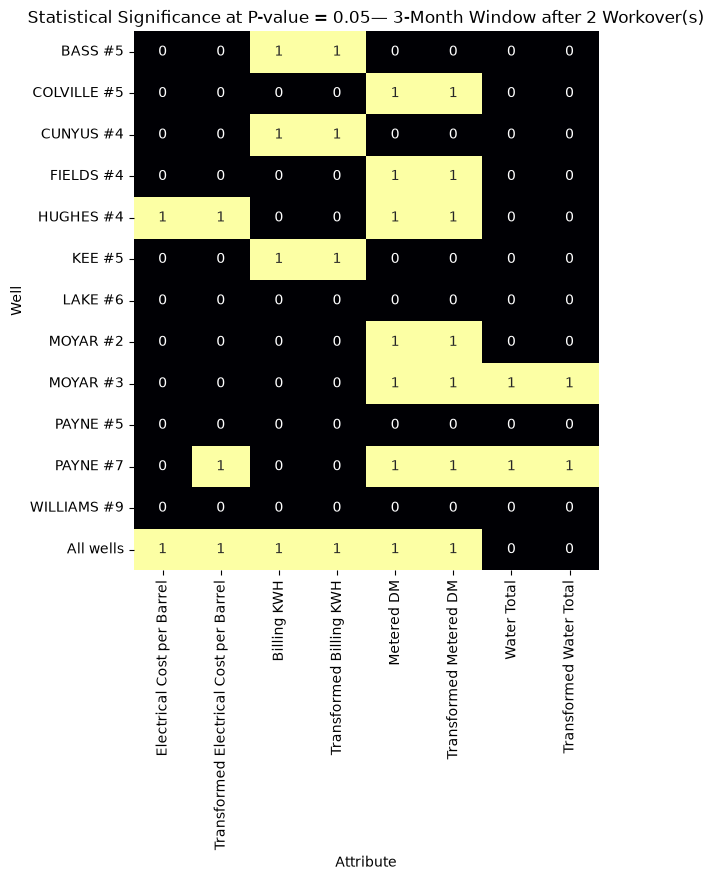

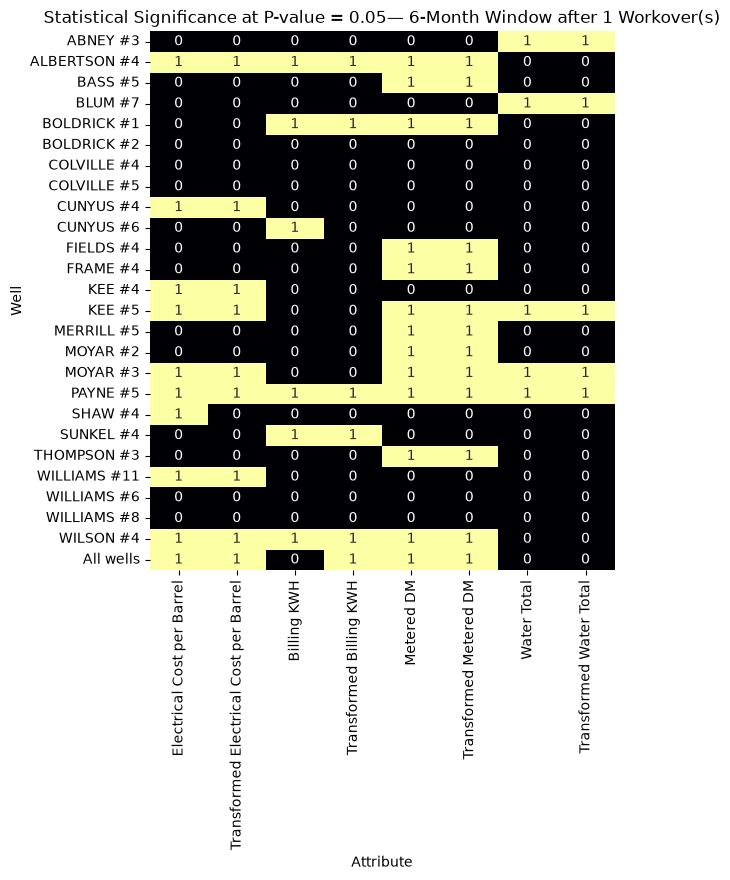

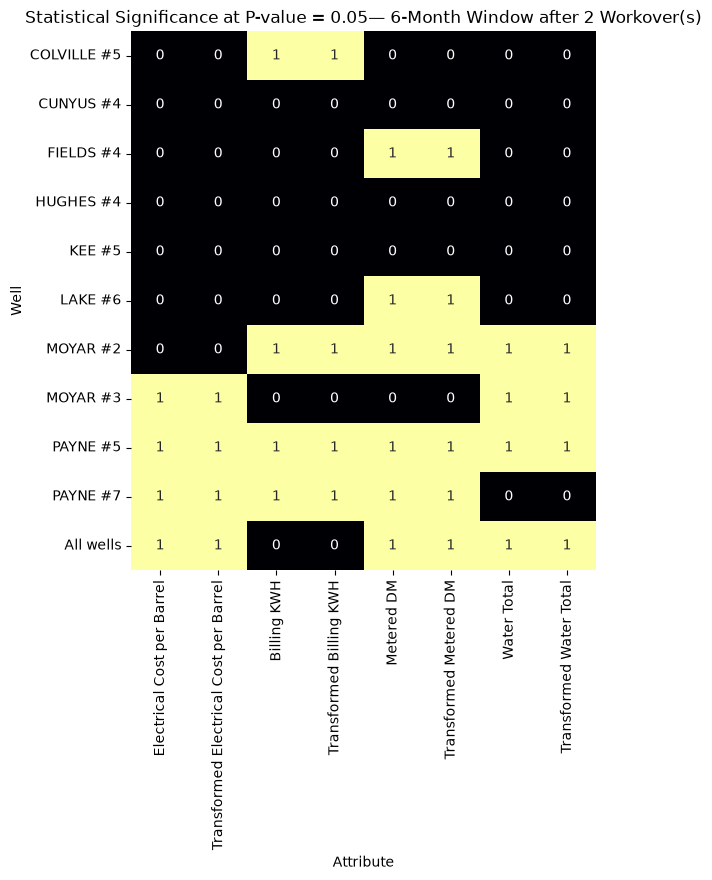

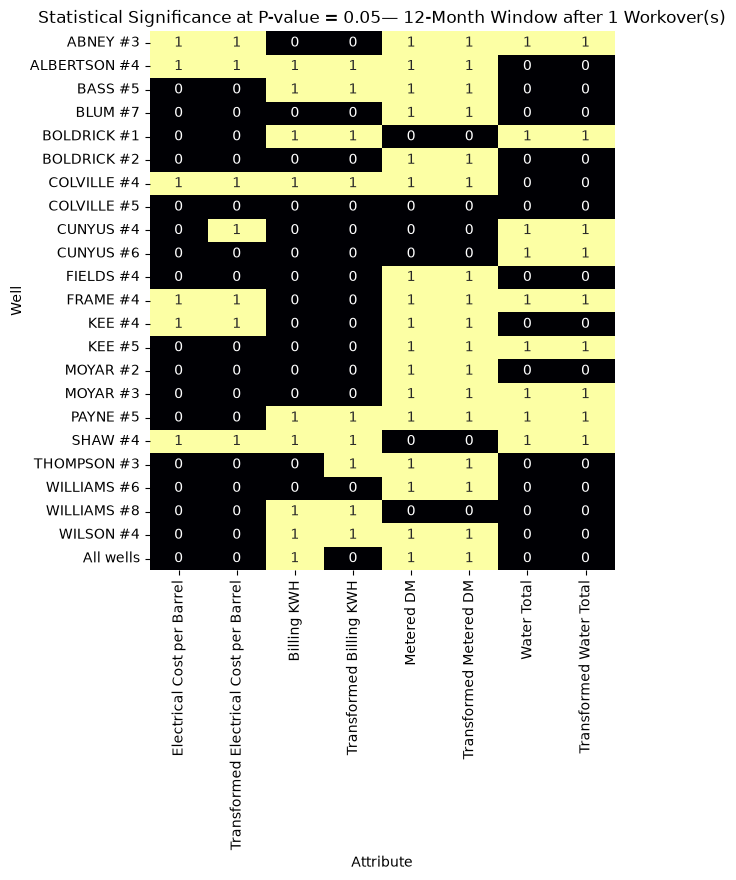

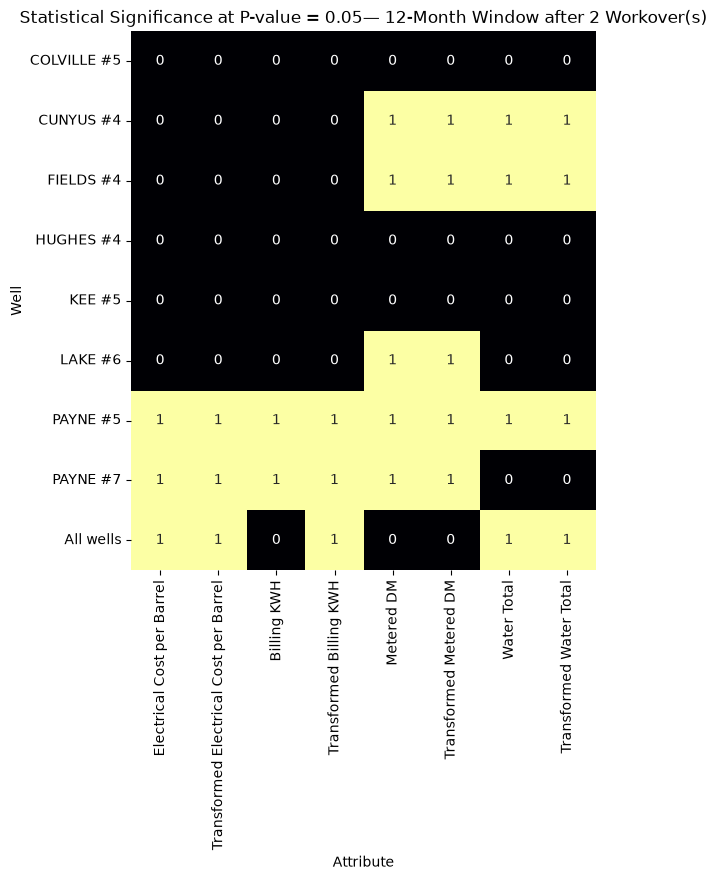

In [42]:
attribute_order = [
    "Electrical Cost per Barrel",
    "Transformed Electrical Cost per Barrel",
    "Billing KWH",
    "Transformed Billing KWH",
    "Metered DM",
    "Transformed Metered DM",
    "Water Total",
    "Transformed Water Total"
]

window_test = [3, 6, 12]
workovers_test = [1,2]
for window in window_test:
    for work in workovers_test:
        #creating the dataframe for the binary matrix using the lists above
        window_df = Paired_Sample_df[(Wilcoxon_df["Months"] == window) & (Wilcoxon_df["Workover"] == work)]
        binary_matrix = window_df.pivot(index = "Well", columns = "Attribute", values = "Significant .05")
        binary_matrix = binary_matrix.astype(int)
        #changing the order of the columns
        binary_matrix = binary_matrix.reindex(columns = attribute_order)
        #changing the order of the index
        well_order = [
            well for well in binary_matrix.index
            if well != "All wells"
        ]
        
        if "All wells" in binary_matrix.index:
            well_order.append("All wells")
        
        binary_matrix = binary_matrix.reindex(well_order)
        
        #plotting the heatmap figure
        plt.figure(figsize=(6, 7))
        sns.heatmap(
            binary_matrix, 
            annot = True,
            cmap = "inferno",
            vmin = 0,
            vmax = 1,
            cbar = False
        )
        
        plt.title(f"Statistical Significance at P-value = 0.05— {window}-Month Window after {work} Workover(s)")
        plt.xlabel("Attribute")
        plt.ylabel("Well")
        filename = f"Wilcoxon_T-test_Binary_Matrix_{window}_{work}.jpeg"
        plt.savefig(filename, dpi=200, bbox_inches="tight")
        
        plt.show()

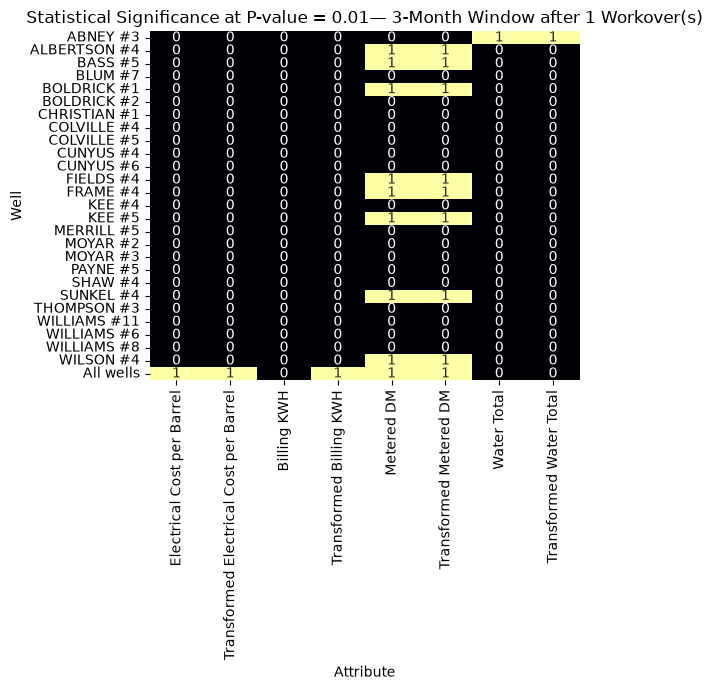

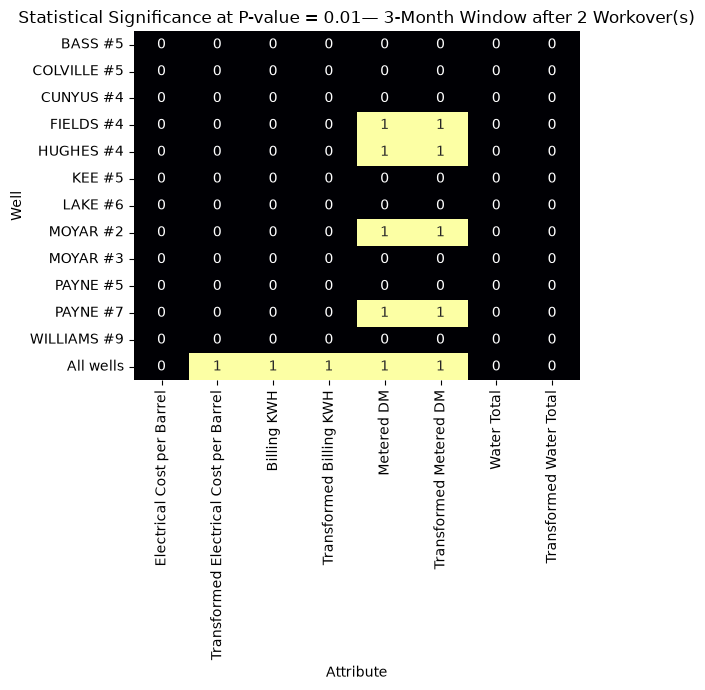

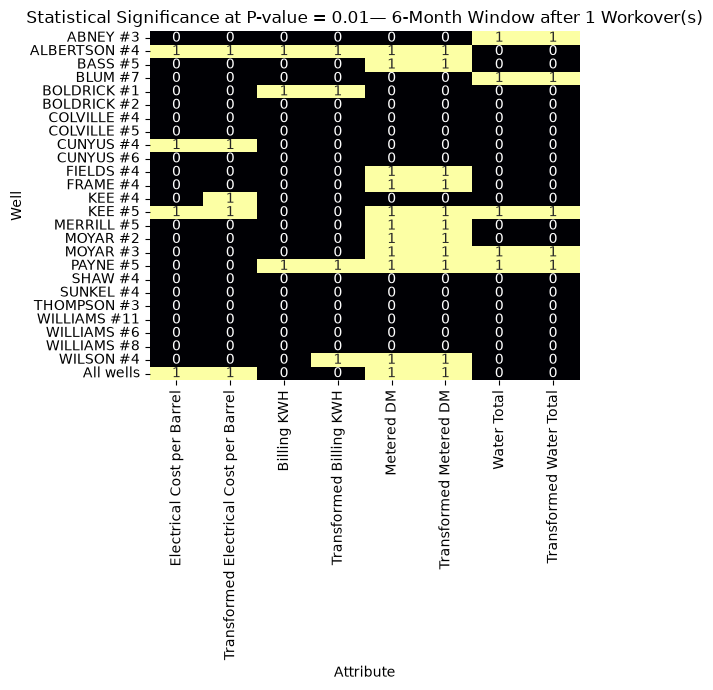

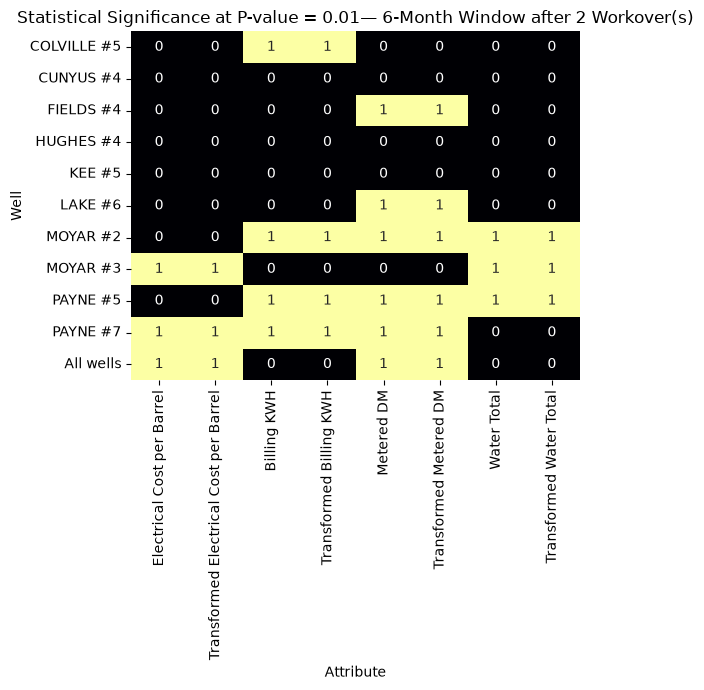

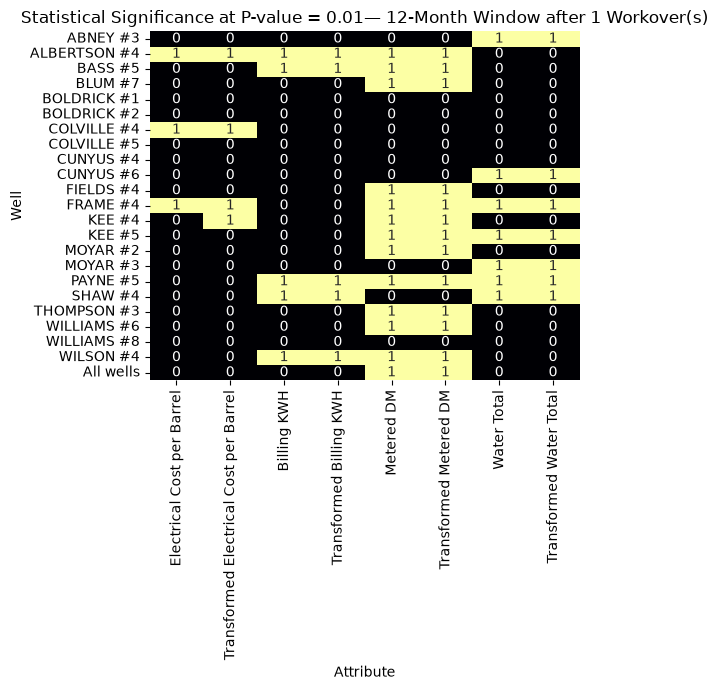

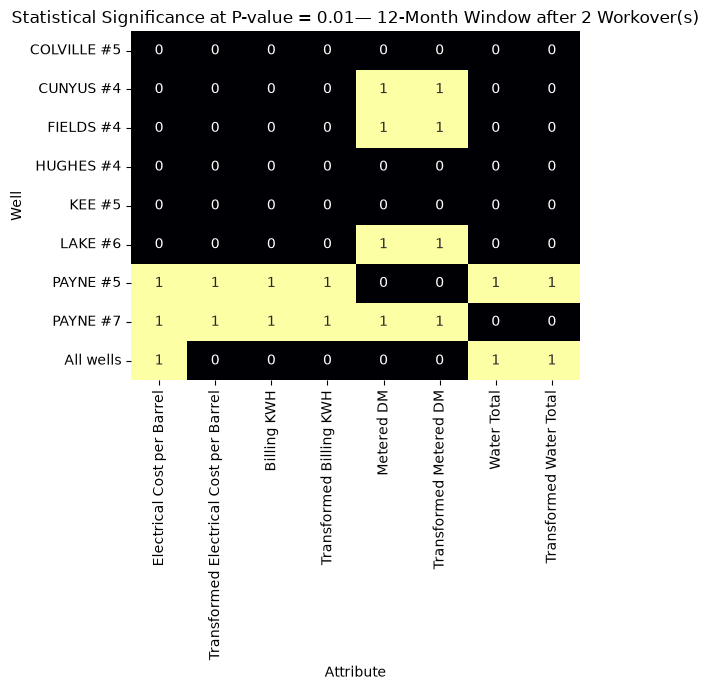

In [20]:
attribute_order = [
    "Electrical Cost per Barrel",
    "Transformed Electrical Cost per Barrel",
    "Billing KWH",
    "Transformed Billing KWH",
    "Metered DM",
    "Transformed Metered DM",
    "Water Total",
    "Transformed Water Total"
]

window_test = [3, 6, 12]
workovers_test = [1,2]
for window in window_test:
    for work in workovers_test:
        #creating the dataframe for the binary matrix using the lists above
        window_df = Paired_Sample_df[(Paired_Sample_df["Months"] == window) & (Paired_Sample_df["Workover"] == work)]
        binary_matrix = window_df.pivot(index = "Well", columns = "Attribute", values = "Significant .01")
        binary_matrix = binary_matrix.astype(int)
        #changing the order of the columns
        binary_matrix = binary_matrix.reindex(columns = attribute_order)
        #changing the order of the index
        well_order = [
            well for well in binary_matrix.index
            if well != "All wells"
        ]
        
        if "All wells" in binary_matrix.index:
            well_order.append("All wells")
        
        binary_matrix = binary_matrix.reindex(well_order)
        
        #plotting the heatmap figure
        plt.figure(figsize=(6, 7))
        sns.heatmap(
            binary_matrix, 
            annot = True,
            cmap = "inferno",
            vmin = 0,
            vmax = 1,
            cbar = False
        )
        
        plt.title(f"Statistical Significance at P-value = 0.01— {window}-Month Window after {work} Workover(s)")
        plt.xlabel("Attribute")
        plt.ylabel("Well")
        plt.tight_layout()
        #plt.show()